# Task 3 · Augmentation
Random crop (shift of up to 4 px), rotation (up to 15°), zoom (up to 1.4×) and horizontal and vertical flips, drawn
anew for every image in every epoch. The Task 1 CNN is retrained for 15 epochs without augmentation, with each
transformation alone and with three combinations.

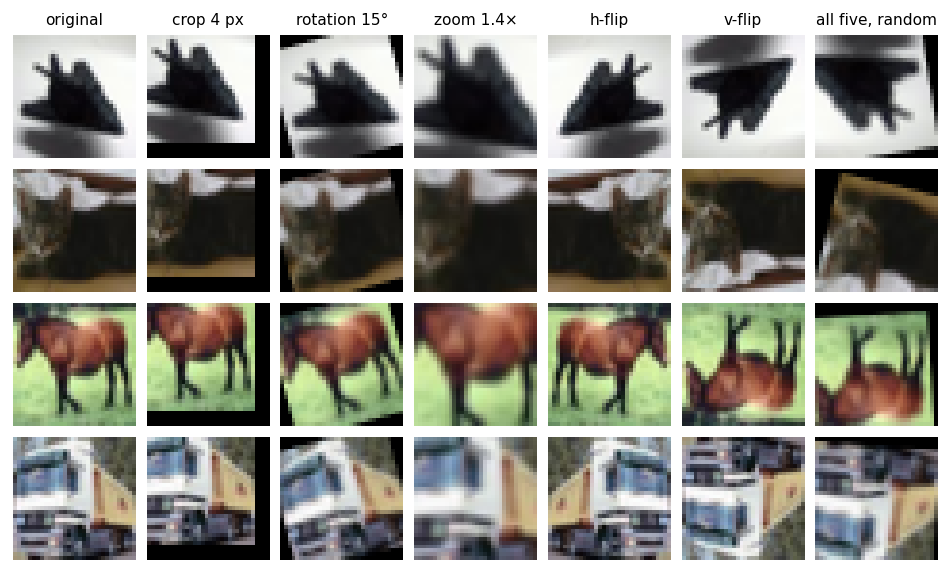

In [1]:
from hw3 import *
from sklearn.metrics import confusion_matrix

B = json.load(open(BEST))['cnn']
X, Y, _, Yte = cifar()
torch.manual_seed(SEED)
ops = {'original': (), 'crop 4 px': ('crop',), 'rotation 15°': ('rotation',), 'zoom 1.4×': ('zoom',),
       'h-flip': ('h-flip',), 'v-flip': ('v-flip',), 'all five, random': OPS}
fig, axes = plt.subplots(4, len(ops), figsize=(7.2, 4.3))
for r, c in enumerate((0, 3, 7, 9)):
    i = int((Y == c).nonzero()[0])
    for ax, (t, op) in zip(axes[r], ops.items()):
        img = augment(X[i:i + 1], op, fixed=op != OPS)[0]
        ax.imshow((img / 255).clamp(0, 1).permute(1, 2, 0))
        ax.set_title(t if r == 0 else '')
        ax.axis('off')
save(fig, 'transforms')

In [2]:
E = 15
base = dict(model=partial(CNN, B['arch']), lr=B['lr'], epochs=E)
V = {'none': (), **{o: (o,) for o in OPS}, 'crop + h-flip': ('crop', 'h-flip'), 'all but v-flip': OPS[:4], 'all five': OPS}
key = {k: 'aug_' + {(): 'none', OPS[:4]: 'novflip', OPS: 'all'}.get(v, '_'.join(v)) for k, v in V.items()}
R = cv({key[k]: base | dict(aug=v) for k, v in V.items()})
R = {k: R[key[k]] for k in V}
T = pd.DataFrame({k: {'train acc': ms(last(R[k], 'train_acc')), 'val acc': ms(last(R[k], 'val_acc')),
                      'test acc': ms(last(R[k], 'test_acc')), 'gap (pp)': ms(last(R[k], 'train_acc') - last(R[k], 'val_acc')),
                      'test vs none (pp)': pdiff(R[k], R['none']) if V[k] else '--'} for k in V}).T
rows('t3_table', T)
T

,train acc,val acc,test acc,gap (pp),test vs none (pp)
none,100.0 (0.0),81.5 (0.3),80.9 (0.2),18.5 (0.3),--
crop,91.7 (0.3),83.5 (0.4),83.1 (0.1),8.1 (0.6),"+2.1 (0.2), 5/5 folds"
rotation,96.1 (0.2),81.9 (0.4),81.6 (0.3),14.2 (0.4),"+0.7 (0.3), 5/5 folds"
zoom,94.6 (0.3),80.2 (0.7),79.8 (0.5),14.3 (0.6),"-1.2 (0.5), 0/5 folds"
h-flip,97.6 (0.2),83.8 (0.3),83.2 (0.2),13.9 (0.4),"+2.3 (0.1), 5/5 folds"
v-flip,94.9 (0.1),78.6 (0.2),78.3 (0.2),16.3 (0.4),"-2.7 (0.1), 0/5 folds"
crop + h-flip,88.4 (0.1),83.8 (0.5),83.3 (0.2),4.5 (0.6),"+2.4 (0.2), 5/5 folds"
all but v-flip,81.2 (0.3),78.1 (0.4),77.8 (0.4),3.1 (0.2),"-3.2 (0.4), 0/5 folds"
all five,72.3 (0.6),70.6 (0.4),70.0 (0.5),1.7 (0.7),"-10.9 (0.5), 0/5 folds"


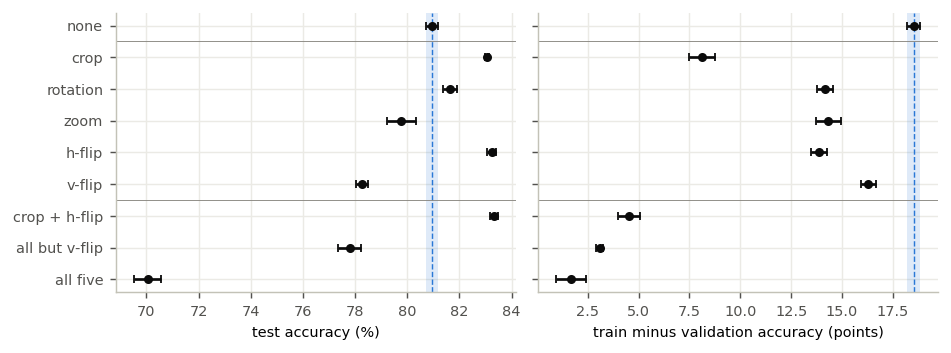

In [3]:
A = {m: np.array([last(R[k], m) for k in V]) * 100 for m in ('train_acc', 'val_acc', 'test_acc')}
fig, axes = plt.subplots(1, 2, figsize=(7.2, 2.6), sharey=True)
y = -np.arange(len(V))
for ax, v, t in zip(axes, (A['test_acc'], A['train_acc'] - A['val_acc']),
                    ('test accuracy (%)', 'train minus validation accuracy (points)')):
    ax.axvspan(*v[0].mean() + np.array([-1, 1]) * v[0].std(ddof=1), color=COL['cnn'], alpha=.15, lw=0)
    ax.axvline(v[0].mean(), color=COL['cnn'], ls='--', lw=.8)
    ax.errorbar(v.mean(1), y, xerr=v.std(1, ddof=1), fmt='o', ms=4, capsize=2, color=INK)
    for b in (-.5, -5.5):
        ax.axhline(b, color=MUTED, lw=.5)
    ax.set_xlabel(t)
axes[0].set_yticks(y, list(V))
save(fig, 'aug_ablation')

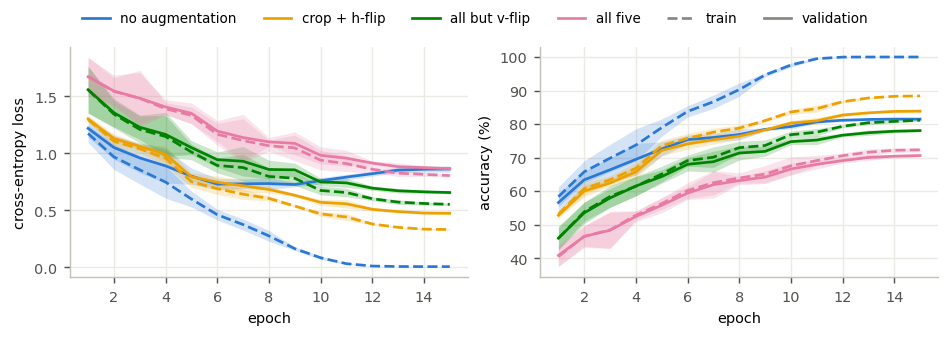

In [4]:
G = {'no augmentation': ('none', COL['cnn']), 'crop + h-flip': ('crop + h-flip', COL['crop']),
     'all but v-flip': ('all but v-flip', COL['novflip']), 'all five': ('all five', COL['all'])}
fig, axes = plt.subplots(1, 2, figsize=(7.2, 2.5))
curves({k: (R[n], c) for k, (n, c) in G.items()}, axes)
save(fig, 'aug_curves')

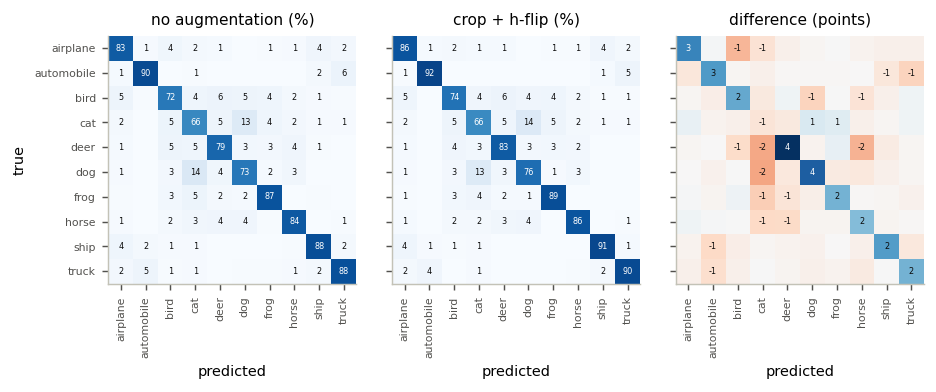

In [5]:
conf = {k: np.array([confusion_matrix(Yte, r['pred'], normalize='true') for r in R[k]]) * 100 for k in V}
top = max(list(V)[1:], key=lambda k: last(R[k], 'val_acc').mean())
D = conf[top].mean(0) - conf['none'].mean(0)
fig, axes = plt.subplots(1, 3, figsize=(7.2, 2.9))
for ax, M, t, cmap, lim in zip(axes, (conf['none'].mean(0), conf[top].mean(0), D),
                               ('no augmentation (%)', f'{top} (%)', 'difference (points)'),
                               ('Blues', 'Blues', 'RdBu'), (100, 100, np.abs(D).max())):
    ax.imshow(M, cmap=cmap, vmin=-lim if cmap == 'RdBu' else 0, vmax=lim)
    for (r, c), v in np.ndenumerate(M):
        if round(v):
            ax.text(c, r, f'{v:.0f}', ha='center', va='center', fontsize=4.5, color='white' if abs(v) > .6 * lim else INK)
    ax.set_xticks(range(10), CLASSES, rotation=90, fontsize=6)
    ax.set_yticks(range(10), CLASSES, fontsize=6)
    ax.tick_params(labelleft=ax is axes[0])
    ax.set(title=t, xlabel='predicted')
    ax.grid(False)
axes[0].set_ylabel('true')
save(fig, 'confusion')

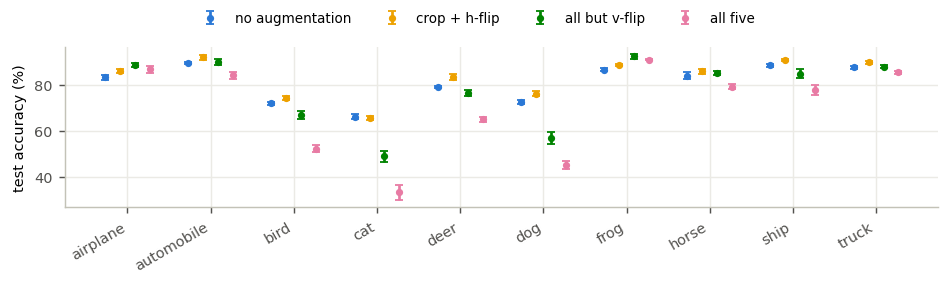

In [6]:
pc = {k: np.array([np.diag(m) for m in conf[k]]) for k in conf}
fig, ax = plt.subplots(figsize=(7.2, 2.1))
for q, (k, (n, c)) in enumerate(G.items()):
    ax.errorbar(np.arange(10) + .18 * (q - 1.5), pc[n].mean(0), pc[n].std(0, ddof=1), fmt='o', ms=3, capsize=2, color=c, label=k)
ax.set_xticks(range(10), CLASSES, rotation=30, ha='right')
ax.set_ylabel('test accuracy (%)')
fig.legend(loc='outside upper center', ncol=4)
save(fig, 'per_class')

In [7]:
g = pc[top] - pc['none']
b, w = g.mean(0).argmax(), g.mean(0).argmin()
name = dict(zip(V, ['None', 'Crop', 'Rotation', 'Zoom', 'Hflip', 'Vflip', 'CropHflip', 'Novflip', 'All']))
tex('t3', augEpochs=E, topName=top, bestClass=CLASSES[b], bestGain=ms(g[:, b], 1, sign='+'), worstClass=CLASSES[w],
    worstGain=ms(g[:, w], 1, sign='+'), augDiff=pdiff(R[top], R['none']),
    vflipDiff=pdiff(R['all five'], R['all but v-flip']), **{m + name[k]: v for k in V for m, v in (
        ('test', T.at[k, 'test acc']), ('val', T.at[k, 'val acc']), ('gap', T.at[k, 'gap (pp)']), ('diff', T.at[k, 'test vs none (pp)']))})